<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_12_Cross_Validation_and_Model_Evaluation_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 12 — Cross-Validation and Model Evaluation Techniques (Validasi Silang dan Teknik Evaluasi Model)

**Referensi:** *scikit-learn Cookbook, Third Edition* — Bab 12

## Tujuan

Skor dari satu kali pembagian data latih dan uji bisa terlalu optimistis atau terlalu pesimistis. Notebook ini membahas cara memperoleh perkiraan kinerja yang lebih andal, membandingkan kandidat model, menyetel hyperparameter, dan memeriksa kemungkinan model dapat bekerja baik pada data baru.

Penjelasan dan alur eksperimen di notebook ini disusun secara mandiri sesuai topik bab, bukan menyalin sel dari notebook referensi satu per satu.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, kamu diharapkan mampu:

- menjelaskan manfaat cross-validation dan kapan stratifikasi diperlukan;
- memilih strategi pembagian data yang sesuai untuk data independen, berkelompok, atau berurutan menurut waktu;
- menafsirkan accuracy, precision, recall, F1-score, ROC-AUC, dan metrik regresi;
- menggunakan `cross_val_score`, `cross_validate`, `GridSearchCV`, dan `RandomizedSearchCV`;
- mengenali nested cross-validation dan sumber umum kebocoran data;
- membaca learning curve dan validation curve sebagai petunjuk kemampuan generalisasi.

## 1. Persiapan dan dataset

Kita mulai dengan dataset Breast Cancer Wisconsin yang tersedia di scikit-learn. Untuk contoh evaluasi ini, kelas positif secara eksplisit didefinisikan sebagai **malignant** (ganas), sehingga recall dapat ditafsirkan sebagai proporsi kasus ganas yang berhasil dikenali.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes, make_classification, make_regression
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit,
    LeaveOneOut, cross_val_score, cross_validate, GridSearchCV,
    RandomizedSearchCV, learning_curve, validation_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, mean_absolute_error,
    mean_squared_error, r2_score
)
from scipy.stats import loguniform

RANDOM_STATE = 2026

In [ ]:
cancer = load_breast_cancer()
X = cancer.data
# Target pada dataset scikit-learn: 0 = malignant (ganas), 1 = benign (jinak).
y = (cancer.target == 0).astype(int)

print(f"Jumlah sampel: {X.shape[0]}")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Kelas positif = malignant (ganas): {y.sum()} cases")
print(f"Kelas negatif = benign (jinak): {(y == 0).sum()} cases")

Jumlah sampel: 569
Jumlah fitur: 30
Kelas positif = malignant (ganas): 212 cases
Kelas negatif = benign (jinak): 357 cases


## 2. Mengapa evaluasi tidak cukup dengan satu pembagian data?

Data hold-out berguna untuk evaluasi akhir yang tidak tersentuh selama pengembangan. Cross-validation melengkapinya dengan melatih model berulang kali pada fold pelatihan yang berbeda dan mengevaluasi pada fold yang disisihkan. Variasi skor antar-fold juga informatif: variasi besar dapat menunjukkan bahwa kinerja sangat bergantung pada observasi yang kebetulan masuk ke sampel.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

baseline_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
baseline_pipe.fit(X_train, y_train)
holdout_pred = baseline_pipe.predict(X_test)

print(f"Akurasi hold-out:          {accuracy_score(y_test, holdout_pred):.3f}")
print(f"Balanced accuracy hold-out: {balanced_accuracy_score(y_test, holdout_pred):.3f}")

Akurasi hold-out:          0.965
Balanced accuracy hold-out: 0.957


### 2.1 K-Fold dibandingkan Stratified K-Fold

Dalam K-Fold biasa, sampel dibagi ke dalam fold tanpa secara khusus mempertahankan proporsi target. `StratifiedKFold` berupaya mempertahankan proporsi tiap kelas pada setiap fold, yang biasanya bermanfaat untuk klasifikasi, terutama jika jumlah tiap kelas berbeda.

In [ ]:
base_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

plain_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
strat_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

plain_scores = cross_val_score(base_model, X, y, cv=plain_cv, scoring="accuracy")
strat_scores = cross_val_score(base_model, X, y, cv=strat_cv, scoring="accuracy")

cv_comparison = pd.DataFrame({
    "Splitter": ["KFold"] * len(plain_scores) + ["StratifiedKFold"] * len(strat_scores),
    "Fold": list(range(1, 6)) * 2,
    "Akurasi": np.r_[plain_scores, strat_scores]
})
display(cv_comparison)
print(f"Rata-rata ± SD KFold:           {plain_scores.mean():.3f} ± {plain_scores.std(ddof=1):.3f}")
print(f"StratifiedRata-rata ± SD KFold: {strat_scores.mean():.3f} ± {strat_scores.std(ddof=1):.3f}")

,Splitter,Fold,Akurasi
0,KFold,1,0.991228
1,KFold,2,0.982456
2,KFold,3,0.991228
3,KFold,4,0.973684
4,KFold,5,0.964602
5,StratifiedKFold,1,1.000000
6,StratifiedKFold,2,0.964912
7,StratifiedKFold,3,0.956140
8,StratifiedKFold,4,0.973684
9,StratifiedKFold,5,0.991150


Rata-rata ± SD KFold:           0.981 ± 0.012
StratifiedRata-rata ± SD KFold: 0.977 ± 0.018


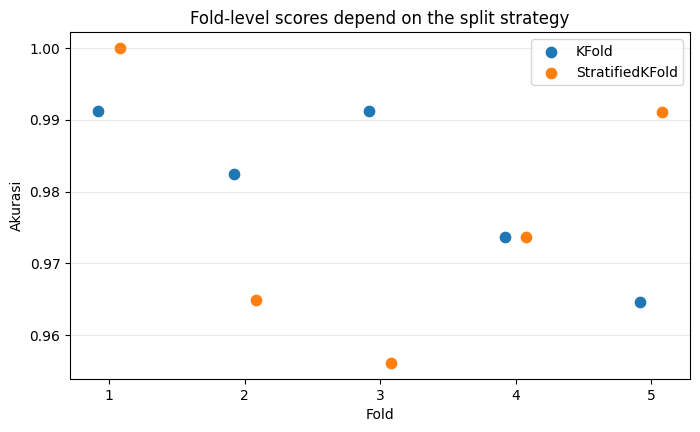

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, values, offset in [
    ("KFold", plain_scores, -0.08),
    ("StratifiedKFold", strat_scores, 0.08)
]:
    x_positions = np.arange(1, 6) + offset
    ax.scatter(x_positions, values, s=55, label=label)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Fold")
ax.set_ylabel("Akurasi")
ax.set_title("Fold-level scores depend on the split strategy")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

**Petunjuk interpretasi:** bandingkan nilai rata-rata dan sebaran skor antar-fold. Stratifikasi tidak selalu meningkatkan skor rata-rata; tujuan utamanya adalah menjaga agar proporsi kelas di setiap fold lebih mewakili dataset.

## 3. Strategi cross-validation lanjutan

Struktur data yang berbeda memerlukan strategi pembagian yang berbeda. Mencampur observasi secara acak tidak tepat ketika beberapa catatan berasal dari orang/perangkat yang sama atau ketika prediksi masa depan harus dibuat berdasarkan data masa lalu.

### 3.1 GroupKFold: menjaga catatan terkait tetap dalam kelompok

Contoh sintetis ini menggambarkan pengukuran berulang yang dikelompokkan berdasarkan entitas. Dalam satu fold, satu grup tidak boleh muncul sekaligus pada data latih dan validasi karena model bisa memanfaatkan pola khusus dari entitas yang sama.

In [ ]:
X_group, y_group = make_classification(
    n_samples=480, n_features=12, n_informative=7, n_redundant=2,
    weights=[0.65, 0.35], random_state=RANDOM_STATE
)
groups = np.repeat(np.arange(60), 8)  # 60 entities, 8 records each
group_cv = GroupKFold(n_splits=5)

group_scores = cross_val_score(
    Pipeline([("scale", StandardScaler()),
              ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
    X_group, y_group, cv=group_cv, groups=groups, scoring="balanced_accuracy"
)
print("Balanced accuracy GroupKFold per fold:", np.round(group_scores, 3))
print(f"Rata-rata: {group_scores.mean():.3f}")

Balanced accuracy GroupKFold per fold: [0.774 0.841 0.794 0.866 0.868]
Rata-rata: 0.829


### 3.2 TimeSeriesSplit: validasi bergerak maju menurut waktu

Untuk observasi yang tersusun menurut waktu, data validasi harus berada setelah data latih. `TimeSeriesSplit` memperluas jendela data latih dan mengevaluasi pada segmen waktu berikutnya, alih-alih mengacak urutan waktu.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n_time = 240
time_index = np.arange(n_time)
X_time = np.column_stack([
    time_index / n_time,
    np.sin(time_index / 12),
    rng.normal(0, 0.2, n_time)
])
y_time = 2.5 * X_time[:, 0] + 0.8 * X_time[:, 1] + rng.normal(0, 0.15, n_time)

time_cv = TimeSeriesSplit(n_splits=5)
time_model = Ridge(alpha=1.0)
time_scores = cross_val_score(time_model, X_time, y_time, cv=time_cv, scoring="neg_mean_absolute_error")
print("MAE pada pemisahan ke depan:", np.round(-time_scores, 3))
print(f"Rata-rata MAE validasi ke depan: {-time_scores.mean():.3f}")

MAE pada pemisahan ke depan: [0.175 0.591 0.22  0.261 0.132]
Rata-rata MAE validasi ke depan: 0.276


### 3.3 Leave-One-Out dan nested cross-validation

- **Leave-One-Out (LOOCV)** melakukan validasi menggunakan satu sampel pada setiap putaran. Hampir semua data digunakan untuk setiap pelatihan, tetapi jumlah proses fitting menjadi banyak dan dapat menghabiskan waktu komputasi.
- **Nested cross-validation** menempatkan pemilihan hyperparameter pada loop bagian dalam dan pengukuran kinerja pada loop bagian luar. Cara ini mengurangi optimisme yang mungkin terjadi jika skor validasi yang sama digunakan untuk memilih sekaligus melaporkan model.

In [ ]:
diabetes = load_diabetes()
X_reg, y_reg = diabetes.data, diabetes.target

loo = LeaveOneOut()
loo_mse_scores = cross_val_score(
    Ridge(alpha=1.0), X_reg, y_reg, cv=loo, scoring="neg_mean_squared_error"
)
print(f"Rata-rata MSE LOOCV:  {-loo_mse_scores.mean():.1f}")
print(f"Rata-rata RMSE LOOCV: {np.sqrt(-loo_mse_scores.mean()):.1f}")

Rata-rata MSE LOOCV:  3327.7
Rata-rata RMSE LOOCV: 57.7


In [ ]:
inner_search = GridSearchCV(
    estimator=Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=5,
    scoring="r2",
    n_jobs=1
)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

nested_r2 = cross_val_score(inner_search, X_reg, y_reg, cv=outer_cv, scoring="r2", n_jobs=1)
print("R² Nested CV per fold luar:", np.round(nested_r2, 3))
print(f"Rata-rata R² Nested CV: {nested_r2.mean():.3f} ± {nested_r2.std(ddof=1):.3f}")

R² Nested CV per fold luar: [0.538 0.468 0.434 0.535 0.491]
Rata-rata R² Nested CV: 0.493 ± 0.045


## 4. Metrik evaluasi model

Setiap metrik menjawab pertanyaan yang berbeda. Accuracy menghitung proporsi prediksi yang benar; precision berfokus pada keandalan prediksi positif; recall mengukur jumlah kasus positif sebenarnya yang ditemukan; F1 menggabungkan precision dan recall. ROC-AUC mengevaluasi kemampuan pengurutan prediksi pada berbagai ambang probabilitas.

In [ ]:
metric_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=0.5, max_iter=3000, random_state=RANDOM_STATE))
])
metric_pipe.fit(X_train, y_train)
test_pred = metric_pipe.predict(X_test)
test_probability = metric_pipe.predict_proba(X_test)[:, 1]

metrics = pd.Series({
    "Akurasi": accuracy_score(y_test, test_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision (malignant)": precision_score(y_test, test_pred, zero_division=0),
    "Recall (malignant)": recall_score(y_test, test_pred, zero_division=0),
    "F1 (malignant)": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probability)
})
display(metrics.to_frame("Test score").round(3))
print(classification_report(y_test, test_pred, target_names=["benign", "malignant"], zero_division=0))

,Test score
Akurasi,0.965
Balanced accuracy,0.957
Precision (malignant),0.980
Recall (malignant),0.925
F1 (malignant),0.951
ROC-AUC,0.985


              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        90
   malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



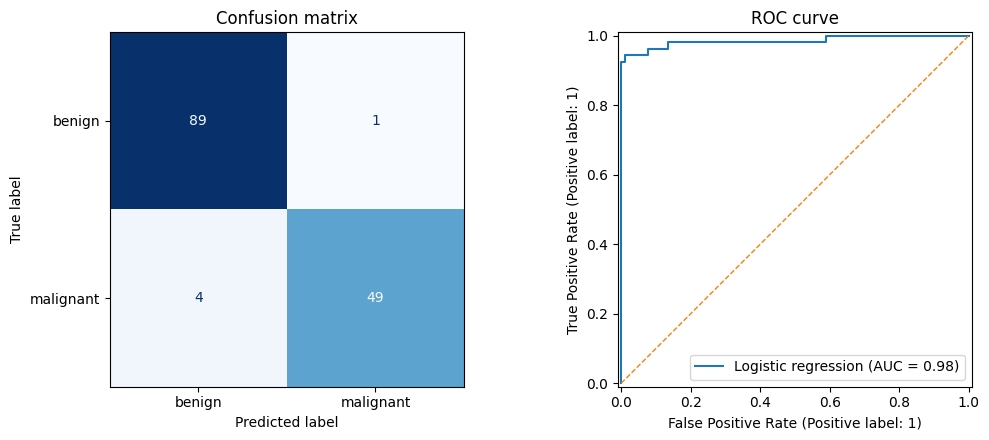

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["benign", "malignant"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

### Metrik regresi dan arah penilaian skor

Untuk regresi, metrik umum mencakup mean absolute error (MAE), mean squared error (MSE), dan koefisien determinasi \(R^2\). Nilai MAE/MSE yang lebih kecil lebih baik, sedangkan nilai \(R^2\) yang lebih tinggi umumnya lebih baik. Pada API penilaian scikit-learn, nilai loss sering ditampilkan sebagai bilangan negatif (misalnya `neg_mean_squared_error`) agar aturan umum “skor lebih tinggi lebih baik” tetap berlaku.

In [ ]:
reg_model = Ridge(alpha=1.0)
reg_cv = cross_validate(
    reg_model, X_reg, y_reg,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring={"mae": "neg_mean_absolute_error",
             "mse": "neg_mean_squared_error",
             "r2": "r2"},
    return_train_score=True,
    n_jobs=1
)
reg_summary = pd.Series({
    "CV MAE": -reg_cv["test_mae"].mean(),
    "CV RMSE": np.sqrt(-reg_cv["test_mse"].mean()),
    "CV R²": reg_cv["test_r2"].mean()
})
display(reg_summary.to_frame("Mean score").round(3))

,Mean score
CV MAE,48.935
CV RMSE,58.448
CV R²,0.421


## 5. Menerapkan cross-validation di scikit-learn

`cross_val_score` praktis untuk mengevaluasi satu metrik. `cross_validate` mengembalikan beberapa metrik dan dapat melaporkan waktu fitting serta penilaian. Dengan menempatkan prapemrosesan di dalam `Pipeline`, setiap fold mempelajari parameter scaling hanya dari bagian data latihnya.

In [ ]:
multi_metric = cross_validate(
    baseline_pipe, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    return_train_score=True,
    n_jobs=1
)
multi_metric_summary = pd.DataFrame({
    "Metric": ["accuracy", "precision", "recall", "f1", "roc_auc"],
    "CV mean": [multi_metric[f"test_{m}"].mean()
                for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]],
    "CV SD": [multi_metric[f"test_{m}"].std(ddof=1)
              for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]]
})
display(multi_metric_summary.round(3))

,Metric,CV mean,CV SD
0,accuracy,0.977,0.018
1,precision,0.981,0.020
2,recall,0.958,0.042
3,f1,0.969,0.025
4,roc_auc,0.995,0.006


## 6. Pemilihan model: grid search dan randomized search

Pencarian hyperparameter membandingkan konfigurasi kandidat menggunakan cross-validation. Grid search mengevaluasi semua nilai yang dicantumkan, sedangkan randomized search mengambil sejumlah kandidat dari distribusi yang ditentukan. Skor validasi digunakan untuk memilih model; data uji terpisah sebaiknya tidak disentuh sampai evaluasi akhir.

In [ ]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
search_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [ ]:
grid = GridSearchCV(
    estimator=search_pipe,
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0]},
    cv=search_cv,
    scoring="roc_auc",
    n_jobs=1,
    return_train_score=True
)
grid.fit(X_train2, y_train2)
print("Parameter terbaik Grid Search:", grid.best_params_)
print(f"Rata-rata ROC-AUC CV terbaik: {grid.best_score_:.3f}")

Parameter terbaik Grid Search: {'model__C': 1.0}
Rata-rata ROC-AUC CV terbaik: 0.997


In [ ]:
grid_table = pd.DataFrame(grid.cv_results_)[
    ["param_model__C", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
].sort_values("rank_test_score")
display(grid_table.round(3))

,param_model__C,mean_test_score,std_test_score,mean_train_score,rank_test_score
2,1.00,0.997,0.004,0.999,1
1,0.10,0.997,0.005,0.999,2
3,10.00,0.996,0.005,1.000,3
0,0.01,0.993,0.010,0.996,4


In [ ]:
random_search = RandomizedSearchCV(
    estimator=search_pipe,
    param_distributions={"model__C": loguniform(1e-3, 1e2)},
    n_iter=12,
    cv=search_cv,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=True
)
random_search.fit(X_train2, y_train2)
print("Parameter terbaik Randomized Search:", random_search.best_params_)
print(f"Rata-rata ROC-AUC CV terbaik: {random_search.best_score_:.3f}")

Parameter terbaik Randomized Search: {'model__C': np.float64(0.6183730791532684)}
Rata-rata ROC-AUC CV terbaik: 0.997


In [ ]:
final_model = random_search.best_estimator_
final_pred = final_model.predict(X_test2)
final_prob = final_model.predict_proba(X_test2)[:, 1]

print(f"Akurasi data hold-out: {accuracy_score(y_test2, final_pred):.3f}")
print(f"ROC-AUC data hold-out: {roc_auc_score(y_test2, final_prob):.3f}")
print("Pengingat: jangan terus menyetel model dengan mengacu pada data uji hold-out ini.")

Akurasi data hold-out: 0.965
ROC-AUC data hold-out: 0.985
Pengingat: jangan terus menyetel model dengan mengacu pada data uji hold-out ini.


### Menghindari kebocoran data (*data leakage*)

Setiap transformasi yang mempelajari informasi dari data—seperti scaling, imputasi, pemilihan fitur, atau reduksi dimensi—pada umumnya hanya boleh di-*fit* pada bagian pelatihan dari setiap fold. Pipeline membuat batas ini lebih jelas. Memilih fitur atau menyetel parameter setelah berulang kali memeriksa data uji akhir juga membocorkan informasi ke proses pengembangan.

## 7. Menilai kemampuan generalisasi melalui kurva

Learning curve mengubah jumlah data pelatihan yang digunakan. Validation curve mengubah satu hyperparameter. Keduanya tidak membuktikan bahwa kinerja model di produksi akan selalu sama, tetapi dapat membantu mendiagnosis bias tinggi, varians tinggi, dan sensitivitas terhadap pengaturan hyperparameter.

In [ ]:
curve_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(C=0.5, max_iter=3000, random_state=RANDOM_STATE))
])
sizes, train_scores, valid_scores = learning_curve(
    curve_model, X, y,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="accuracy",
    n_jobs=1
)

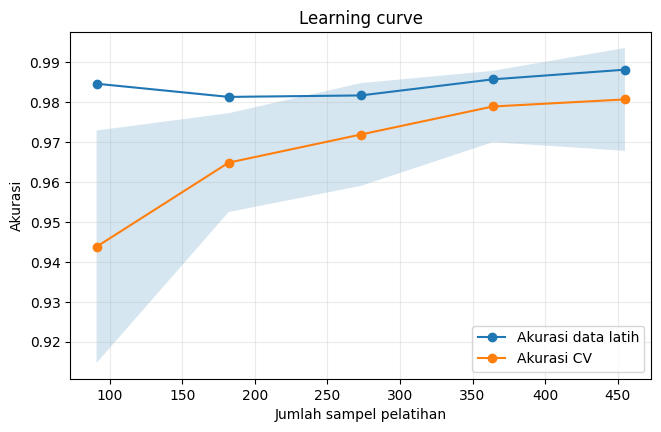

In [ ]:
plt.figure(figsize=(7.5, 4.5))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Akurasi data latih")
plt.plot(sizes, valid_scores.mean(axis=1), marker="o", label="Akurasi CV")
plt.fill_between(
    sizes,
    valid_scores.mean(axis=1) - valid_scores.std(axis=1),
    valid_scores.mean(axis=1) + valid_scores.std(axis=1),
    alpha=0.18
)
plt.xlabel("Jumlah sampel pelatihan")
plt.ylabel("Akurasi")
plt.title("Learning curve")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [ ]:
c_values = np.logspace(-3, 2, 7)
train_curve, valid_curve = validation_curve(
    search_pipe, X_train2, y_train2,
    param_name="model__C",
    param_range=c_values,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc",
    n_jobs=1
)

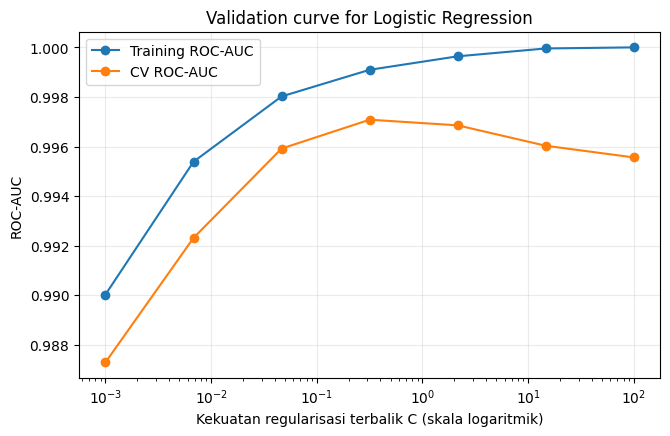

In [ ]:
plt.figure(figsize=(7.5, 4.5))
plt.semilogx(c_values, train_curve.mean(axis=1), marker="o", label="Training ROC-AUC")
plt.semilogx(c_values, valid_curve.mean(axis=1), marker="o", label="CV ROC-AUC")
plt.xlabel("Kekuatan regularisasi terbalik C (skala logaritmik)")
plt.ylabel("ROC-AUC")
plt.title("Validation curve for Logistic Regression")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 8. Latihan praktis

Selesaikan latihan berikut setelah menjalankan notebook. Berikan interpretasimu sendiri dan jangan hanya menyalin angka hasil yang ditampilkan.

### Latihan 1 — Membandingkan strategi validasi

1. Jalankan `KFold` dan `StratifiedKFold` dengan 3, 5, dan 10 fold.
2. Catat rata-rata dan standar deviasi F1-score.
3. Jelaskan pengaturan mana yang akan kamu laporkan dan alasannya.

### Latihan 2 — Menyetel model dengan dua metode pencarian

1. Tambahkan setidaknya dua nilai `C` ke ruang parameter grid search.
2. Ubah distribusi atau jumlah iterasi randomized search.
3. Bandingkan biaya komputasi dan skor rata-rata cross-validation terbaik.
4. Evaluasi estimator terpilih satu kali pada data uji yang tidak digunakan dalam penyetelan.

### Latihan 3 — Mendiagnosis generalisasi

1. Ubah ukuran data pelatihan pada learning curve.
2. Periksa garis skor pelatihan dan validasi.
3. Gunakan validation curve untuk menjelaskan pengaruh regularisasi yang lebih kuat dan lebih lemah.
4. Tuliskan dua perbaikan konkret yang akan kamu uji berikutnya.

## Ringkasan bab

- Cross-validation memperkirakan kinerja model melalui beberapa pembagian data latih/validasi.
- Stratifikasi membantu menjaga proporsi kelas; pembagian berbasis grup dan waktu mengatasi struktur ketergantungan data yang berbeda.
- Pemilihan metrik perlu mempertimbangkan biaya kesalahan dan jenis masalah prediksi.
- `cross_val_score`, `cross_validate`, dan kelas pencarian menyediakan alur evaluasi serta penyetelan yang semakin fleksibel.
- Nested cross-validation memisahkan pemilihan hyperparameter dari evaluasi pada loop luar.
- Learning curve dan validation curve membantu diagnosis, sementara data uji akhir yang terpisah tetap penting.
- Tempatkan prapemrosesan di dalam pipeline dan jangan gunakan data uji selama penyetelan agar risiko kebocoran data berkurang.